# PPO – Proximal Policy Optimization
**Moheeb Abusamra (248690)** · ANN 26CSCI33H · Phase 2 · RL track

This notebook trains PPO on the 4 shared MuJoCo tasks, runs 8 experiments (the baseline + 7 single changes), and logs everything to TensorBoard.
The environments, seeds, training budget, test rule re from this file: `common_rl.py` which is common for entire group to make sure we all are compared equally and work on same environments, so the results can be compared directly with MBPO, SAC and TD3.

**Setup**
```
conda create -n ann python=3.12 -y
conda activate ann
pip install torch --index-url https://download.pytorch.org/whl/cu128
pip install -r requirements.txt
```

## 1. Setup
Imports, the shared team settings from `common_rl.py` 

In [8]:
import os, json, time, glob, shutil
import numpy as np
import torch
import torch.nn as nn
import gymnasium as gym
import matplotlib.pyplot as plt
from torch.distributions import Normal

from common_rl import ENVS, SEEDS, GAMMA, LOG_ROOT, EVAL_SEED_OFFSET, set_seed, make_env, RunLogger, results_table

DEVICE = torch.device("cpu")

print("Device :", DEVICE, "-", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "no GPU found, using CPU")
print("Seeds  :", SEEDS, "| gamma:", GAMMA)
for env_id, settings in ENVS.items():
    print(f"{env_id:20s} budget {settings['total_steps']:>7,} steps | test every {settings['eval_every']:,} steps")

Device : cpu - no GPU found, using CPU
Seeds  : [0, 1, 2] | gamma: 0.99
InvertedPendulum-v5  budget  50,000 steps | test every 2,000 steps
Hopper-v5            budget 300,000 steps | test every 10,000 steps
Walker2d-v5          budget 300,000 steps | test every 10,000 steps
HalfCheetah-v5       budget 300,000 steps | test every 10,000 steps


### Data, preprocessing and metrics (shared with the team)
- **Data:** there is no fixed dataset. The data is generated by interacting with 4 MuJoCo environments (Gymnasium v5), with the same versions, budgets and seeds for all four team models (`common_rl.py`).
- **Preprocessing (PPO):** actions are clipped to the valid range, observations are normalized with a running mean/std, rewards are scaled by the running std of the discounted return, both are clipped to [-10, 10]. The `no_norm` experiment removes this.
- **Training metrics (TensorBoard):** `train/episodic_return`, `losses/actor_loss` and `losses/critic_loss`, plus PPO diagnostics (`ppo/approx_kl`, `ppo/clip_fraction`, `ppo/max_ratio`, `ppo/entropy`, `ppo/explained_variance`).
- **Test metrics (shared):** `test/mean_return` = 10 deterministic episodes on a separate env every 10k steps (2k for InvertedPendulum). Final score = mean of the last 3 tests, reported as mean ± std over 3 seeds.

## 2. Hyperparameters and experiments

**Baseline:** the standard PPO settings for MuJoCo reported by Engstrom et al. and Ilyas et al. (ICLR 2020).
Every experiment changes **one** setting and keeps the rest at baseline, so any difference in results comes from that one change.

Some settings never change, so they are written directly in the code:

| Fixed setting | Value | Where |
|---|---|---|
| Discount γ | 0.99 (`GAMMA`, shared with the team) | training function |
| Network | 2 hidden layers × 64 units, tanh | network cell |
| Adam betas / eps | (0.9, 0.999) / 1e-5 | training function |
| Observation and reward clip | [-10, 10] | training function |

| Experiment | Change | Hypothesis |
|---|---|---|
| `baseline` | none | Reference point for all other runs. |
| `clip_0.1` / `clip_0.3` | clip range ε | Smaller ε → smaller, safer policy steps (slower but more stable). Larger ε → faster but less stable, with a higher KL and max ratio. |
| `epochs_5` / `epochs_20` | epochs per batch | More epochs learn more from each batch but let the policy drift further (higher KL). This may cause instability or collapse. |
| `no_norm` | observation and reward normalization off | Engstrom et al. found much of PPO's performance comes from these code-level tricks, so we expect a clear drop. |
| `iter_1024` / `iter_4096` | env steps per iteration | Fewer steps → noisier but more frequent updates. More steps → smoother but fewer updates. The minibatch size stays at 64, so the total number of gradient steps is the same. |

In [ ]:
BASELINE = {
    "learning_rate":  3e-4,   # Adam step size, decayed linearly to 0 during training
    "num_steps":      2048,   # iteration size: env steps collected before each update
    "minibatch_size": 64,     # samples per gradient step
    "update_epochs":  10,     # how many times each batch is reused
    "clip_eps":       0.2,    # PPO clip range: the ratio is clipped to [1 - eps, 1 + eps]
    "gae_lambda":     0.95,   # GAE lambda: bias vs variance of the advantage
    "vf_coef":        0.5,    # weight of the value (critic) loss
    "ent_coef":       0.0,    # entropy bonus (0 in the reference papers)
    "max_grad_norm":  0.5,    # gradient clipping
    "normalize":      True,   # observation + reward normalization
}


SPECS = {
    "baseline":  {},
    "clip_0.1":  {"clip_eps": 0.1},
    "clip_0.3":  {"clip_eps": 0.3},
    "epochs_5":  {"update_epochs": 5},
    "epochs_20": {"update_epochs": 20},
    "no_norm":   {"normalize": False},
    "iter_1024": {"num_steps": 1024},
    "iter_4096": {"num_steps": 4096},
}
print(len(SPECS), "experiments x", len(ENVS), "environments x", len(SEEDS), "seeds =", len(SPECS) * len(ENVS) * len(SEEDS), "runs")

8 experiments x 4 environments x 3 seeds = 96 runs


## 3. The network
There are two separate MLPs, each with 2 hidden layers of 64 tanh units:
- **actor:** gives the mean μ(s) of a Gaussian policy. `log_std` is a separate learned number per joint that doesn't depend on the state, and it sets how random the actions are.
- **critic:** gives the state value V(s).

Weights use orthogonal initialization: √2 for hidden layers, 0.01 for the actor's last layerand 1.0 for the critic's last layer.


In [ ]:
class ActorCritic(nn.Module):
    def __init__(self, obs_dim, act_dim):
        super().__init__()
        self.actor = nn.Sequential(nn.Linear(obs_dim, 64), nn.Tanh(),
                                   nn.Linear(64, 64), nn.Tanh(),
                                   nn.Linear(64, act_dim))
        self.log_std = nn.Parameter(torch.zeros(act_dim))    
        self.critic = nn.Sequential(nn.Linear(obs_dim, 64), nn.Tanh(),
                                    nn.Linear(64, 64), nn.Tanh(),
                                    nn.Linear(64, 1))

      
        for net, last_layer_gain in [(self.actor, 0.01), (self.critic, 1.0)]:
            nn.init.orthogonal_(net[0].weight, np.sqrt(2))
            nn.init.orthogonal_(net[2].weight, np.sqrt(2))
            nn.init.orthogonal_(net[4].weight, last_layer_gain)
            for i in (0, 2, 4):
                nn.init.zeros_(net[i].bias)

    def forward(self, obs, action=None):
        policy = Normal(self.actor(obs), self.log_std.exp())   # pi(a|s) = Normal(mean(s), sigma)
        if action is None:
            action = policy.sample()
        log_prob = policy.log_prob(action).sum(-1)              
        entropy = policy.entropy().sum(-1)
        value = self.critic(obs).squeeze(-1)
        return action, log_prob, entropy, value

## 4. The training function
`train_ppo` trains one run (one experiment, one environment, one seed) from start to finish.

**Environment.** It starts from the shared `make_env` (Gymnasium defaults + episode statistics). PPO's wrappers go on top:
- action clipping
- observation normalization (running mean/std)
- reward scaling, with both observations and rewards clipped to [-10, 10]

The `no_norm` experiment skips the normalization.

**Each iteration has 4 steps:**
1. **Collect** `num_steps` environment steps with the current policy.
2. **Advantages with GAE**, walking backwards through the batch:
   - δ = r + γ·V(next) − V(now)
   - A = δ + γλ·A(next)
   - The critic's target is A + V.
3. **Update** for `update_epochs` epochs over shuffled minibatches, using the PPO clipped objective:
$$L^{CLIP} = -\mathbb{E}\left[\min\left(r_t A_t,\ \text{clip}(r_t, 1-\epsilon, 1+\epsilon) A_t\right)\right], \quad r_t = \frac{\pi_{new}(a_t|s_t)}{\pi_{old}(a_t|s_t)}$$
   Total loss = policy loss + 0.5 · value loss − 0 · entropy.
4. **Log** to TensorBoard and run the shared test when it is due.

**PPO diagnostics** :
- **approx KL:** how far the policy moved.
- **clip fraction:** share of samples where clipping was active.
- **max ratio:** the largest r, which shows whether the trust region really holds.

An episode ending by time limit is treated like a terminal state, as in the reference PPO code.
At the end of each run, I save the trained network is as `model.pt` and the diagnostics as `ppo_diagnostics.json`.

In [ ]:
def train_ppo(env_id, seed, spec, cfg, total_steps=None):
    total_steps = total_steps or ENVS[env_id]["total_steps"]
    set_seed(seed)
    env = make_env(env_id, seed)                   
    env = gym.wrappers.ClipAction(env)             
    obs_normalizer = None
    if cfg["normalize"]:
        env = obs_normalizer = gym.wrappers.NormalizeObservation(env)
        env = gym.wrappers.TransformObservation(env, lambda o: np.clip(o, -10, 10), env.observation_space)
        env = gym.wrappers.NormalizeReward(env, gamma=GAMMA)
        env = gym.wrappers.TransformReward(env, lambda r: np.clip(r, -10, 10))

    agent = ActorCritic(env.observation_space.shape[0], env.action_space.shape[0]).to(DEVICE)
    optimizer = torch.optim.Adam(agent.parameters(), lr=cfg["learning_rate"], betas=(0.9, 0.999), eps=1e-5)
    logger = RunLogger("PPO", spec, env_id, seed, hparams=cfg)

    def test_action(raw_obs):
        if obs_normalizer is not None:
            mean, var = obs_normalizer.obs_rms.mean, obs_normalizer.obs_rms.var
            raw_obs = np.clip((raw_obs - mean) / np.sqrt(var + 1e-8), -10, 10)
        with torch.no_grad():
            return agent.actor(torch.tensor(raw_obs, dtype=torch.float32, device=DEVICE)).cpu().numpy()

    n_steps = cfg["num_steps"]
    n_iterations = total_steps // n_steps
    clip_eps = cfg["clip_eps"]
    all_kls, all_clip_fractions, overall_max_ratio = [], [], 0.0
    obs, _ = env.reset(seed=seed)
    step = 0
    start_time = time.time()

    for iteration in range(n_iterations):
        lr = cfg["learning_rate"] * (1 - iteration / n_iterations)     
        optimizer.param_groups[0]["lr"] = lr

       
        batch_obs, batch_actions, batch_log_probs, rewards, dones, values = [], [], [], [], [], []
        for _ in range(n_steps):
            step += 1
            with torch.no_grad():
                action, log_prob, _, value = agent(torch.tensor(obs, dtype=torch.float32, device=DEVICE))
            action = action.cpu().numpy()
            next_obs, reward, terminated, truncated, info = env.step(action)
            logger.log_train_episodes(step, info)

            batch_obs.append(obs)
            batch_actions.append(action)
            batch_log_probs.append(log_prob.item())
            rewards.append(reward)
            dones.append(terminated or truncated)
            values.append(value.item())

            obs = env.reset()[0] if (terminated or truncated) else next_obs

       
        with torch.no_grad():
            next_value = agent.critic(torch.tensor(obs, dtype=torch.float32, device=DEVICE)).item()   
        rewards = np.array(rewards, dtype=np.float32)
        values = np.array(values, dtype=np.float32)
        advantages = np.zeros(n_steps, dtype=np.float32)
        gae = 0.0
        for t in reversed(range(n_steps)):
            if dones[t]:                      
                next_value, gae = 0.0, 0.0
            delta = rewards[t] + GAMMA * next_value - values[t]
            gae = delta + GAMMA * cfg["gae_lambda"] * gae
            advantages[t] = gae
            next_value = values[t]
        returns = advantages + values         

       
        obs_t        = torch.tensor(np.array(batch_obs), dtype=torch.float32, device=DEVICE)
        actions_t    = torch.tensor(np.array(batch_actions), dtype=torch.float32, device=DEVICE)
        old_logp_t   = torch.tensor(batch_log_probs, dtype=torch.float32, device=DEVICE)
        advantages_t = torch.tensor(advantages, device=DEVICE)
        returns_t    = torch.tensor(returns, device=DEVICE)

        kls, clip_fractions, max_ratio = [], [], 0.0
        for epoch in range(cfg["update_epochs"]):
            for idx in torch.randperm(n_steps, device=DEVICE).split(cfg["minibatch_size"]):
                _, new_logp, entropy, new_value = agent(obs_t[idx], actions_t[idx])
                log_ratio = new_logp - old_logp_t[idx]
                ratio = log_ratio.exp()                                   
                adv = advantages_t[idx]
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)             

                policy_loss = -torch.min(ratio * adv, ratio.clamp(1 - clip_eps, 1 + clip_eps) * adv).mean()
                value_loss = 0.5 * ((new_value - returns_t[idx]) ** 2).mean()
                loss = policy_loss + cfg["vf_coef"] * value_loss - cfg["ent_coef"] * entropy.mean()

                optimizer.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(agent.parameters(), cfg["max_grad_norm"])
                optimizer.step()

                kls.append(((ratio - 1) - log_ratio).mean().item())
                clip_fractions.append(((ratio - 1).abs() > clip_eps).float().mean().item())
                max_ratio = max(max_ratio, ratio.max().item())

       
        logger.log_losses(step, policy_loss.item(), value_loss.item())
        logger.log(step, "ppo/approx_kl", np.mean(kls))
        logger.log(step, "ppo/clip_fraction", np.mean(clip_fractions))
        logger.log(step, "ppo/max_ratio", max_ratio)
        logger.log(step, "ppo/entropy", entropy.mean().item())
        logger.log(step, "ppo/explained_variance", 1 - np.var(returns - values) / (np.var(returns) + 1e-8))
        logger.log(step, "ppo/learning_rate", lr)
        logger.log(step, "ppo/steps_per_sec", step / (time.time() - start_time))
        logger.maybe_evaluate(step, test_action)

        all_kls += kls
        all_clip_fractions += clip_fractions
        overall_max_ratio = max(overall_max_ratio, max_ratio)

    
    torch.save({"model": agent.state_dict(),
                "obs_mean": torch.tensor(obs_normalizer.obs_rms.mean) if obs_normalizer else None,
                "obs_var":  torch.tensor(obs_normalizer.obs_rms.var) if obs_normalizer else None},
               os.path.join(logger.dir, "model.pt"))
    with open(os.path.join(logger.dir, "ppo_diagnostics.json"), "w") as f:
        json.dump({"mean_approx_kl": float(np.mean(all_kls)),
                   "mean_clip_fraction": float(np.mean(all_clip_fractions)),
                   "max_ratio": overall_max_ratio}, f, indent=2)
    logger.close()
    env.close()
    return logger.final_score()

## 5. Quick test
This runs a short baseline on Hopper (20,480 steps) to check that everything works

In [9]:
start = time.time()
train_ppo("Hopper-v5", seed=0, spec="smoke_test", cfg=BASELINE, total_steps=20_480)
steps_per_sec = 20_480 / (time.time() - start)
shutil.rmtree(os.path.join(LOG_ROOT, "Hopper-v5", "PPO", "smoke_test"))

all_steps = sum(settings["total_steps"] for settings in ENVS.values()) * len(SEEDS) * len(SPECS)
print(f"\nSpeed on {DEVICE}: {steps_per_sec:,.0f} steps/sec")
print(f"Estimated time for all {len(SPECS) * len(ENVS) * len(SEEDS)} runs: {all_steps / steps_per_sec / 3600:.1f} hours")
print(f"Estimated time for the baseline only: {all_steps / len(SPECS) / steps_per_sec / 3600:.1f} hours")

[PPO|smoke_test|Hopper-v5|seed0] step 10240: test return 175.3 ± 1.0
[PPO|smoke_test|Hopper-v5|seed0] step 20480: test return 217.4 ± 1.0
Done: final score 196.3, 0.3 min -> runs\Hopper-v5\PPO\smoke_test\seed0

Speed on cpu: 1,028 steps/sec
Estimated time for all 96 runs: 6.2 hours
Estimated time for the baseline only: 0.8 hours


## 6. Run all experiments
The runs go in order: every environment and seed of `baseline` first, then the next experiment, and so on.


In [11]:
RUN_SPECS = list(SPECS)

for spec in RUN_SPECS:
    cfg = {**BASELINE, **SPECS[spec]}                 # baseline settings, with this experiment's change
    for env_id in ENVS:
        for seed in SEEDS:
            run_dir = os.path.join(LOG_ROOT, env_id, "PPO", spec, f"seed{seed}")
            if os.path.exists(os.path.join(run_dir, "summary.json")):
                print(f"skip (already done): {spec} | {env_id} | seed{seed}")
                continue
            shutil.rmtree(run_dir, ignore_errors=True)  # remove an unfinished run before restarting it
            train_ppo(env_id, seed, spec, cfg)

[PPO|baseline|InvertedPendulum-v5|seed0] step 2048: test return 21.4 ± 0.9
[PPO|baseline|InvertedPendulum-v5|seed0] step 4096: test return 55.2 ± 2.7
[PPO|baseline|InvertedPendulum-v5|seed0] step 6144: test return 95.6 ± 6.8
[PPO|baseline|InvertedPendulum-v5|seed0] step 8192: test return 114.8 ± 9.2
[PPO|baseline|InvertedPendulum-v5|seed0] step 10240: test return 182.7 ± 41.7
[PPO|baseline|InvertedPendulum-v5|seed0] step 12288: test return 514.6 ± 89.4
[PPO|baseline|InvertedPendulum-v5|seed0] step 14336: test return 756.2 ± 15.4
[PPO|baseline|InvertedPendulum-v5|seed0] step 16384: test return 1000.0 ± 0.0
[PPO|baseline|InvertedPendulum-v5|seed0] step 18432: test return 1000.0 ± 0.0
[PPO|baseline|InvertedPendulum-v5|seed0] step 20480: test return 1000.0 ± 0.0
[PPO|baseline|InvertedPendulum-v5|seed0] step 22528: test return 1000.0 ± 0.0
[PPO|baseline|InvertedPendulum-v5|seed0] step 24576: test return 1000.0 ± 0.0
[PPO|baseline|InvertedPendulum-v5|seed0] step 26624: test return 1000.0 ± 0

## 7. Results

### 7.1 TensorBoard
This shows the shared tags (`train/`, `test/`, `losses/`, `time/`) and the PPO diagnostics (`ppo/`).

In [21]:
import sys
os.environ["PATH"] = os.path.join(sys.prefix, "Scripts") + os.pathsep + os.environ["PATH"]
%load_ext tensorboard
%tensorboard --logdir runs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


### 7.2 Results table: the team hand-in format
Final score = the mean of the last 3 test evaluations for each seed, shown as mean ± std across the 3 seeds.

In [13]:
table = results_table("PPO")

| Algo | Spec | Env | Final score (mean ± std) | Seeds | Time (min) |
|---|---|---|---|---|---|
| PPO | baseline | HalfCheetah-v5 | 1303.0 ± 30.7 | 3 | 9.6 |
| PPO | baseline | Hopper-v5 | 2531.5 ± 481.4 | 3 | 7.4 |
| PPO | baseline | InvertedPendulum-v5 | 1000.0 ± 0.0 | 3 | 1.0 |
| PPO | baseline | Walker2d-v5 | 923.7 ± 99.1 | 3 | 7.3 |
| PPO | clip_0.1 | HalfCheetah-v5 | 1073.9 ± 142.2 | 3 | 9.6 |
| PPO | clip_0.1 | Hopper-v5 | 1165.3 ± 244.3 | 3 | 9.1 |
| PPO | clip_0.1 | InvertedPendulum-v5 | 1000.0 ± 0.0 | 3 | 1.0 |
| PPO | clip_0.1 | Walker2d-v5 | 1074.5 ± 406.4 | 3 | 10.4 |
| PPO | clip_0.3 | HalfCheetah-v5 | 1620.3 ± 491.0 | 3 | 5.0 |
| PPO | clip_0.3 | Hopper-v5 | 1593.7 ± 1122.6 | 3 | 5.7 |
| PPO | clip_0.3 | InvertedPendulum-v5 | 1000.0 ± 0.0 | 3 | 2.1 |
| PPO | clip_0.3 | Walker2d-v5 | 1823.5 ± 717.0 | 3 | 5.1 |
| PPO | epochs_20 | HalfCheetah-v5 | 1197.7 ± 255.4 | 3 | 7.1 |
| PPO | epochs_20 | Hopper-v5 | 2475.9 ± 1148.8 | 3 | 7.2 |
| PPO | epochs_20 | InvertedPendulum-v5 

### 7.3 PPO diagnostics per experiment
These numbers link the results to the literature review: is the trust region respected (KL, max ratio), and how often clipping is active?
They are averages over seeds and over the whole of training.

In [14]:
print("| Spec | Env | Mean approx KL | Mean clip fraction | Max ratio (1+eps limit) |")
print("|---|---|---|---|---|")
for spec in SPECS:
    clip_limit = 1 + {**BASELINE, **SPECS[spec]}["clip_eps"]
    for env_id in ENVS:
        files = glob.glob(os.path.join(LOG_ROOT, env_id, "PPO", spec, "seed*", "ppo_diagnostics.json"))
        if not files:
            continue
        runs = [json.load(open(f)) for f in files]
        kl = np.mean([r["mean_approx_kl"] for r in runs])
        clip_fraction = np.mean([r["mean_clip_fraction"] for r in runs])
        max_ratio = np.max([r["max_ratio"] for r in runs])
        print(f"| {spec} | {env_id} | {kl:.4f} | {clip_fraction:.3f} | {max_ratio:.2f} ({clip_limit:.1f}) |")

| Spec | Env | Mean approx KL | Mean clip fraction | Max ratio (1+eps limit) |
|---|---|---|---|---|
| baseline | InvertedPendulum-v5 | 0.0062 | 0.075 | 3.18 (1.2) |
| baseline | Hopper-v5 | 0.0066 | 0.086 | 2.84 (1.2) |
| baseline | Walker2d-v5 | 0.0077 | 0.107 | 2.99 (1.2) |
| baseline | HalfCheetah-v5 | 0.0085 | 0.122 | 2.79 (1.2) |
| clip_0.1 | InvertedPendulum-v5 | 0.0023 | 0.111 | 1.81 (1.1) |
| clip_0.1 | Hopper-v5 | 0.0022 | 0.121 | 1.80 (1.1) |
| clip_0.1 | Walker2d-v5 | 0.0025 | 0.146 | 1.81 (1.1) |
| clip_0.1 | HalfCheetah-v5 | 0.0026 | 0.152 | 1.93 (1.1) |
| clip_0.3 | InvertedPendulum-v5 | 0.0111 | 0.058 | 4.32 (1.3) |
| clip_0.3 | Hopper-v5 | 0.0135 | 0.075 | 3.64 (1.3) |
| clip_0.3 | Walker2d-v5 | 0.0155 | 0.091 | 7.81 (1.3) |
| clip_0.3 | HalfCheetah-v5 | 0.0166 | 0.100 | 4.72 (1.3) |
| epochs_5 | InvertedPendulum-v5 | 0.0045 | 0.054 | 2.57 (1.2) |
| epochs_5 | Hopper-v5 | 0.0047 | 0.058 | 2.60 (1.2) |
| epochs_5 | Walker2d-v5 | 0.0050 | 0.063 | 2.64 (1.2) |
| epochs_5 

### 7.4 Test-return curves
The line is the mean across seeds, and the shaded area is ± 1 std. There is one panel per environment and one line per experiment.

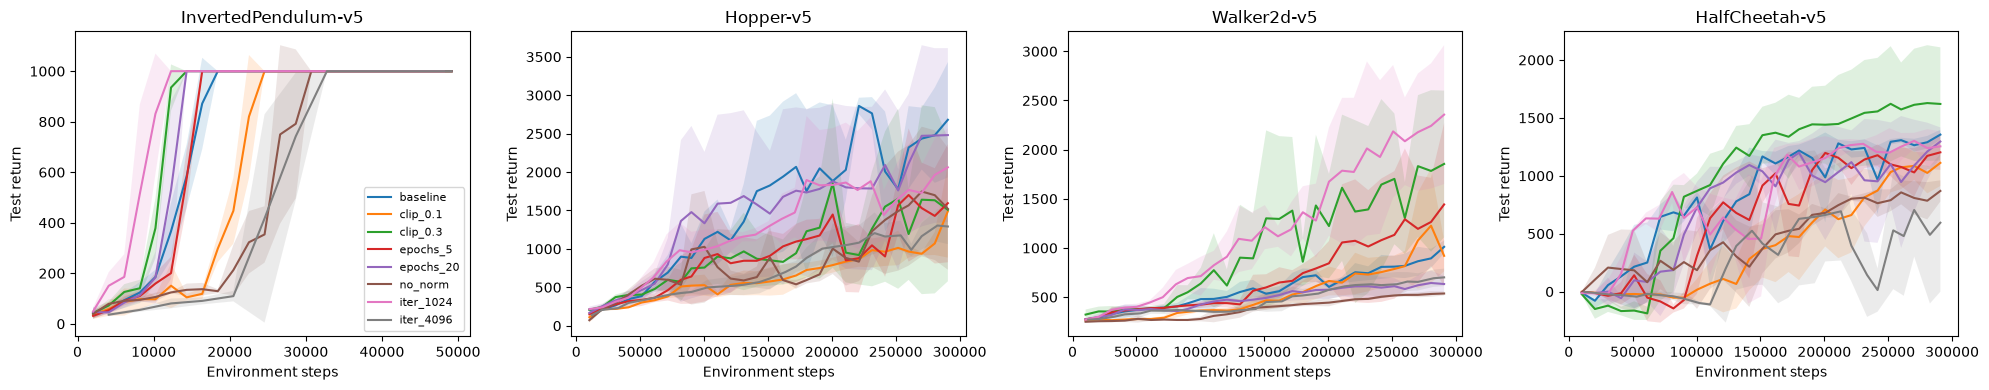

In [ ]:
fig, axes = plt.subplots(1, len(ENVS), figsize=(5 * len(ENVS), 4))
for ax, env_id in zip(axes, ENVS):
    for spec in SPECS:
        files = glob.glob(os.path.join(LOG_ROOT, env_id, "PPO", spec, "seed*", "summary.json"))
        if not files:
            continue
        curves = [np.array(json.load(open(f))["evals"]) for f in files]   
        n = min(len(c) for c in curves)                                   
        steps = curves[0][:n, 0]
        returns = np.array([c[:n, 1] for c in curves])                    
        ax.plot(steps, returns.mean(0), label=spec)
        ax.fill_between(steps, returns.mean(0) - returns.std(0), returns.mean(0) + returns.std(0), alpha=0.15)
    ax.set_title(env_id)
    ax.set_xlabel("Environment steps")
    ax.set_ylabel("Test return")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(LOG_ROOT, "ppo_test_curves.png"), dpi=200)
plt.show()

## 8. Watch the agent
Training doesn't draw anything, because drawing would make it much slower. At the end of every run, the trained network is saved as `model.pt`, and `watch()` loads it and plays one episode:
- `record=False` opens a **live MuJoCo window** where you see the robot move.
- `record=True` saves an **MP4 video** 
- `spec=None` uses an **untrained** network (random weights), to show how model looks before train


In [ ]:
def watch(env_id, spec="baseline", seed=0, record=False, episodes=3, slow_motion=1.0):
    env = gym.make(env_id, render_mode="rgb_array" if record else "human")
    if record:
        env = gym.wrappers.RecordVideo(env, os.path.join(LOG_ROOT, "videos"), episode_trigger=lambda e: True,
                                       name_prefix=f"PPO_{env_id}_{spec or 'untrained'}_seed{seed}")

    agent = ActorCritic(env.observation_space.shape[0], env.action_space.shape[0]).to(DEVICE)
    obs_mean = obs_var = None
    if spec is not None:                                    
        saved = torch.load(os.path.join(LOG_ROOT, env_id, "PPO", spec, f"seed{seed}", "model.pt"), map_location="cpu")
        agent.load_state_dict(saved["model"])
        if saved["obs_mean"] is not None:
            obs_mean, obs_var = saved["obs_mean"].numpy(), saved["obs_var"].numpy()

    for ep in range(episodes):
        obs, _ = env.reset(seed=seed + EVAL_SEED_OFFSET + ep)
        total_reward, steps, done = 0.0, 0, False
        while not done:
            if obs_mean is not None:
                obs = np.clip((obs - obs_mean) / np.sqrt(obs_var + 1e-8), -10, 10)
            with torch.no_grad():
                action = agent.actor(torch.tensor(obs, dtype=torch.float32, device=DEVICE)).cpu().numpy()
            obs, reward, terminated, truncated, _ = env.step(np.clip(action, env.action_space.low, env.action_space.high))
            total_reward += reward
            steps += 1
            done = terminated or truncated
            if not record:
                time.sleep(env.unwrapped.dt * slow_motion)  
        ending = "fell" if terminated else "time limit (1000 steps)"
        print(f"PPO | {env_id} | {spec or 'untrained'} | seed{seed} | episode {ep + 1}: return {total_reward:.1f}, {steps} steps, ended by {ending}")
    env.close()

In [29]:
# Here we can watch whatever specific run
watch("Hopper-v5", spec=None)         
watch("HalfCheetah-v5", spec="clip_0.3", seed=2,slow_motion=4)   

PPO | Hopper-v5 | untrained | seed0 | episode 1: return 114.5, 128 steps, ended by fell
PPO | Hopper-v5 | untrained | seed0 | episode 2: return 103.1, 121 steps, ended by fell
PPO | Hopper-v5 | untrained | seed0 | episode 3: return 111.3, 126 steps, ended by fell
Pressed ESC
Quitting.
PPO | HalfCheetah-v5 | clip_0.3 | seed2 | episode 1: return 2278.5, 1000 steps, ended by time limit (1000 steps)
PPO | HalfCheetah-v5 | clip_0.3 | seed2 | episode 2: return 2394.1, 1000 steps, ended by time limit (1000 steps)
PPO | HalfCheetah-v5 | clip_0.3 | seed2 | episode 3: return 2244.0, 1000 steps, ended by time limit (1000 steps)


In [ ]:
#can save videos mp4
for env_id in ENVS:
    watch(env_id, spec="baseline", record=True)

## 9. Results, discussion and conclusion

### 9.1 Overall
All 96 runs finished (8 experiments × 4 environments × 3 seeds). The final score is the mean of the last 3 test evaluations, reported as mean ± std over the 3 seeds.

| Environment | Baseline final score | Notes |
|---|---|---|
| InvertedPendulum | 1000 ± 0 | Solved (the maximum) after ~16–18k steps in every seed |
| Hopper | 2532 ± 481 | Best of all experiments on this task |
| Walker2d | 924 ± 99 | Still rising at 300k steps: the budget is short for this task |
| HalfCheetah | 1303 ± 31 | Still rising at 300k steps |

The **test** return is higher than the **training** return (Hopper baseline: ≈2,530 vs ≈1,540). That is expected: training actions are sampled with exploration noise, while the test uses the deterministic mean action.

### 9.2 Experiment by experiment (hypothesis → result → why)

| Experiment | Hypothesis | Result (Hopper / Walker2d / HalfCheetah InvertedPendulum steps to reach 1000) | Verdict |
|---|---|---|---|
| `clip_0.1` | Smaller steps: slower but more stable | 1165 / 1075 / 1074 slowest of the clip settings on InvertedPendulum (~24k). KL ≈ ⅓ of baseline (0.0022–0.0026) and entropy stays highest, so the policy moves very little per update. | Slower: **supported**. More stable: not clearly. |
| `clip_0.3` | Bigger steps: faster but less stable | 1594 ± **1123** / 1824 / **1620** (best) fast on InvertedPendulum (~13k). KL ≈ 2× baseline (0.011–0.017), max ratio up to 7.8. Hopper seeds ranged from 600 to 3163. | **Supported**: fast, and the highest variance. |
| `epochs_5` | Learns less from each batch: slower, stays close to the data | 1518 / 1301 / 1135. The lowest clip fraction (~0.06) and a low KL entropy stays high. | **Mostly supported**. |
| `epochs_20` | More drift: higher KL, unstable | 2476 ± **1149** / **633** / 1198. The highest KL and clip fraction among the ε = 0.2 runs (clip fraction 0.20 on HalfCheetah), and entropy collapsed fastest (HalfCheetah 8.2 → 2.5, Walker2d 8.1 → 4.0). On Hopper two seeds reached ~3,290 and one got stuck at 851. | **Supported**. The failure mode is the policy becoming confident (low entropy) too early, more than sudden collapse. |
| `no_norm` | Clearly worse | 1656 / **531** (worst) / 821 slowest on InvertedPendulum (~29k). The critic loss is about 10,000× larger (Hopper ~59 vs 0.004), because the critic must predict raw, unscaled returns. | **Supported**, strongest on Walker2d and HalfCheetah. |
| `iter_1024` | More, noisier updates | 1917 / **2259** (best) / 1265 **fastest** on InvertedPendulum (~10k). Higher late test std (Hopper 327). | **Partly**: noisier, but twice as many updates within 300k steps helped more than the noise hurt. |
| `iter_4096` | Fewer, smoother updates slower start | 1253 / 683 / **596** (worst) slowest on InvertedPendulum (~30k). One HalfCheetah seed never learned to run forward (final 83), but late tests were the most consistent (Hopper std 45). | **Supported**: only 73 updates in 300k steps is too few. |

### 9.3 What the PPO diagnostics show
- **The trust region is not strictly enforced.** The max ratio reached 1.8–7.8 against limits of 1.1–1.3, in every experiment. Clipping removes the *incentive* to move further but does not bound the ratio, which matches Engstrom et al. (2020).
- **KL follows the settings:** clip_0.1 < epochs_5 < baseline ≈ iter_1024 / iter_4096 < epochs_20 < clip_0.3. In every run, KL and clip fraction fall during training as the learning rate decays to 0.
- **Entropy falls in every run, fastest for epochs_20 and clip_0.3:** more aggressive updates lead to a more confident policy and less exploration.
- **Critic quality:** explained variance reaches 0.95–0.99 on Hopper and Walker2d but only 0.2–0.6 on HalfCheetah. HalfCheetah episodes always end at the 1,000-step time limit, which this implementation treats as terminal, so the critic cannot predict the cut-off from the state (see limitations).
- **Seed variance is large.** Many differences are within one standard deviation, so only effects consistent across tasks should be trusted:
  - clip_0.1 learns slower
  - no_norm and iter_4096 are worse
  - clip range and epochs control KL and entropy

### 9.4 Conclusion: which variations performed well and why
- **Best overall:** `iter_1024`, `baseline` and `clip_0.3` (best average rank across the three locomotion tasks). With only 300k steps, PPO is sample-limited because it is on-policy and discards each batch. Settings that update **more often** (iter_1024) or **further** (clip_0.3) used the limited data better, at the cost of more variance between seeds.
- **Worst:** `iter_4096` (too few updates), `no_norm` (the critic cannot fit unscaled returns, so the advantages are poor) and `clip_0.1` (steps too small to learn in time).
- **No single setting was best on every task:** the baseline won on Hopper, iter_1024 on Walker2d and clip_0.3 on HalfCheetah.
- **Main takeaway:** PPO's behaviour is governed by **how far each update moves the policy** (clip range, epochs: visible in KL, clip fraction and max ratio) and **how often it updates** (iteration size). Observation and reward normalization is essential on the harder tasks.

**Limitations:**
- only 3 seeds and 300k steps per task
- time-limit endings are treated as terminal
- one network size (64×64)
- run times were measured on a laptop that was also in use, so they are not compared

